# Unsupervised Learning Using Online Retail Dataset

## Problem understanding, objective, and scope
- **Business problem**: A retailer currently treats all customers the same during marketing campaigns. Meaning high value customers and one-time shoppers are getting the same treatment which is not efficient use of resources. 
- **Objective**: Use unsupervised learning to segment customer into groups based on their purchasing behaviours, to help the business target each segment with more targetted marketing strategies. 
- **Scope**: Customers are described using engineered RFM features: Recency, Frequency, and Monetary value (including Average order value) rather than raw transaction data. 

### 2.1 Load and Explore the Data

In [33]:
df = pd.read_csv(r"C:\Users\jaeth\Downloads\NP\Y2S1\ML1\ml ASG\Dataset\Data\online_retail.csv")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom


In [34]:
print(f'Shape of dataset: {df.shape}\n')
df.info()

Shape of dataset: (541909, 8)

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


Check for missing values

In [35]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Missing Customer details

In [36]:
print(df['CustomerID'].isnull().value_counts())
print(f'% of missing CustomerID: {df['CustomerID'].isnull().mean() * 100:.2f}')
print()
print(df['Description'].isnull().value_counts())
print(f'% of missing Description: {df['Description'].isnull().mean() * 100:.2f}')

CustomerID
False    406829
True     135080
Name: count, dtype: int64
% of missing CustomerID: 24.93

Description
False    540455
True       1454
Name: count, dtype: int64
% of missing Description: 0.27


About 24.9% of rows have a missing CustomerID. Since segmentation tasks is inherently customer-level, these rows cannot be assigned to any customers. Since they cannot be imputed meaningfully, they must be dropped later on in section 2.2. 
Description has only 0.27% missing, which is not used for clustering so it is left alone. 

Summary of numerical features

In [37]:
df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


Check unique counts in key fields

In [38]:
#convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%d/%m/%Y %H:%M')

In [39]:
print('Unique Invoices: ', df['InvoiceNo'].nunique())
print('Unique Customers: ', df['CustomerID'].nunique())
print('Unique Countries: ', df['Country'].nunique())
print(f'Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}')

Unique Invoices:  25900
Unique Customers:  4372
Unique Countries:  38
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


The data set contains 259000 unique invoices, 4372 unique customers, across 38 countries over roughly a one year period from December 2010 to December 2011. This confirms that there is enough cutsomers to segment and that InvoiceDate can be used to calculate Recency for RFM (once a reference data is set).

Distribution of Quantity and UnitPrice

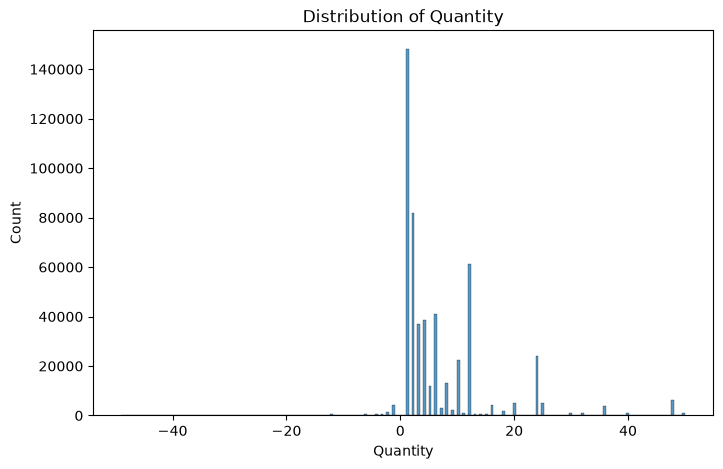

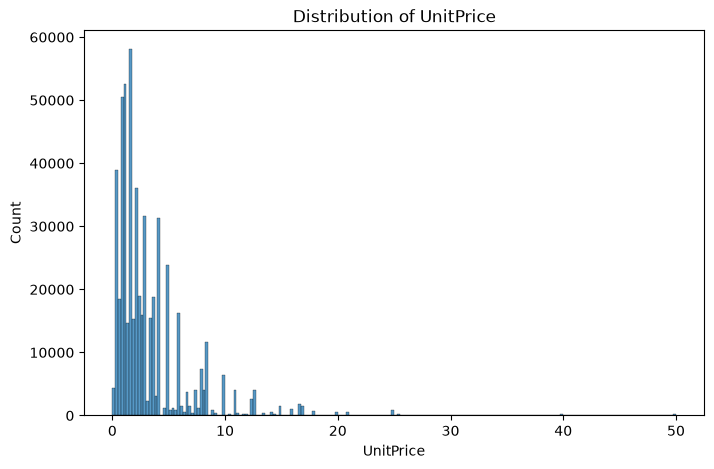

In [40]:
ax1 = plt.figure(figsize=(8,5))
subset_qty = df[(df['Quantity'] > -50) & (df['Quantity'] <= 50)]
ax1 = sns.histplot(subset_qty['Quantity'], bins=200)
ax1 = plt.title('Distribution of Quantity')

ax2 = plt.figure(figsize=(8,5))
subset_price = df[(df['UnitPrice'] > 0) & (df['UnitPrice'] <= 50)]
ax2 = sns.histplot(subset_price['UnitPrice'], bins=200)
ax2 = plt.title('Distribution of UnitPrice')

plt.show()

Both Quantity and UnitPrice are skewed to the right with a small number of outliers. This supports the push of the outlier treatment that will be done in the data cleansing step later. 

Outliers in UnitPrice, Quantity, and invoice totals.

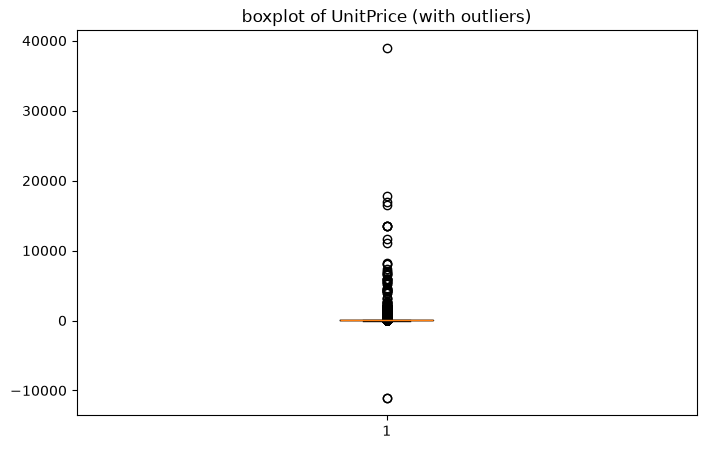

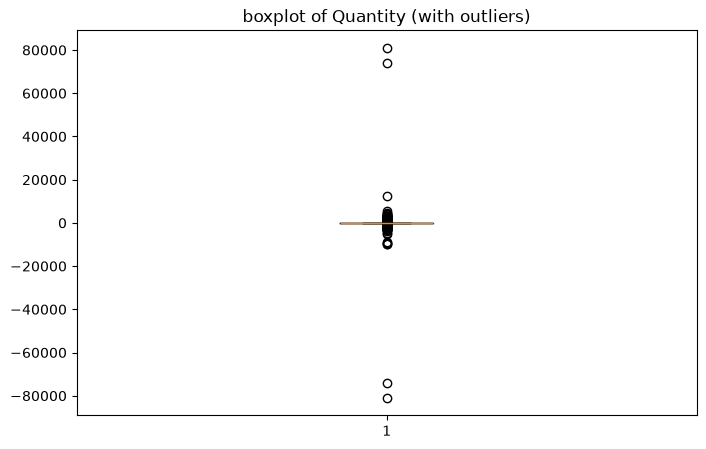

In [41]:
plt.figure(figsize=(8,5))
plt.boxplot(x=df['UnitPrice'])
plt.title('boxplot of UnitPrice (with outliers)')

plt.figure(figsize=(8,5))
plt.boxplot(x=df['Quantity'])
plt.title('boxplot of Quantity (with outliers)')

plt.show()

These boxplots confirm significant outliers in both UnitPrice and Quantity, even including negative Quantity values that correspond to returns or cancellations, which have to be removed later on instead of being kept the same and treated as statistical outliers. 

Check to see how many cancelled invoices to remove later on.

In [42]:
# boolean mask: True where InvoiceNo starts with 'C'
cancelled = df['InvoiceNo'].astype(str).str.startswith('C')

# use the mask to filter the dataframe -> returns the actual rows
cancelled_rows = df[cancelled]

print(f'num of rows to be removed: {cancelled_rows.shape[0]}')  
cancelled_rows[['InvoiceNo', 'CustomerID', 'Quantity', 'UnitPrice', 'InvoiceDate']].head(15)    

num of rows to be removed: 9288


,InvoiceNo,CustomerID,Quantity,UnitPrice,InvoiceDate
141,C536379,14527.0,-1,27.50,2010-12-01 09:41:00
154,C536383,15311.0,-1,4.65,2010-12-01 09:49:00
235,C536391,17548.0,-12,1.65,2010-12-01 10:24:00
236,C536391,17548.0,-24,0.29,2010-12-01 10:24:00
237,C536391,17548.0,-24,0.29,2010-12-01 10:24:00
238,C536391,17548.0,-24,0.29,2010-12-01 10:24:00
239,C536391,17548.0,-12,3.45,2010-12-01 10:24:00
240,C536391,17548.0,-12,1.65,2010-12-01 10:24:00
241,C536391,17548.0,-24,1.65,2010-12-01 10:24:00
939,C536506,17897.0,-6,4.25,2010-12-01 12:38:00


9288 rows from InvoiceNo start with 'C', indicating that they are cancelled invoices, which have negative Quantity values representing returns too. These do not count as genuine purchases so they have to be removed to keep the customer's purchase behaviour as accurate as possible. 

Check to see how many rows have non-positive Quantity or UnitPrice.

In [43]:
print('Rows with non positives:')
print('Quantity: ', (df['Quantity'] <= 0).sum())
print('UnitPrice: ', (df['UnitPrice'] <= 0).sum())

Rows with non positives:
Quantity:  10624
UnitPrice:  2517


Other than cancelled invoices, there are still 10624 rows with non-positive Quantity and 2517 rows with non-positive UnitPrice. These are to be removed since they do not represent valid transactions and would distory the RFM features, specifically monetary (average value).

The top countries sorted by the number of transactions made

In [44]:
df['Country'].value_counts().head(10)

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

The transactions in this dataset are dominated by the United Kingdom, with Germany, France, and EIRE following at a far distance. Observing this imbalance, Country will not be directly used as a clustering feature. RFM behaviour will be treated the same across customers regardless of the country for this analysis.

### 2.2 Cleanse and Transform the Data

Remove cancelled invoices

In [45]:
df_clean = df.dropna(subset=['CustomerID']).copy()
df_clean.shape

(406829, 8)

Remove all cancelled invoices and check that there isn't any more of them.

In [46]:
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
df_clean['InvoiceNo'].astype(str).str.startswith('C').sum()

np.int64(0)

Only keep **valid** records in UnitPrice and Quantity.

In [47]:
df_clean = df_clean[(df_clean['UnitPrice'] > 0) & (df_clean['Quantity'] > 0)]
print(f'num of records now: {df_clean.shape[0]}')

num of records now: 397884


Calculate Invoice totals (`TotPrice`)

In [48]:
df_clean['TotPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']

Find outliers.

In [49]:
def cap_outliers_IQR (data, col):
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    data[col] = data[col].clip(lower=lower, upper=upper)
    return data

for col in ['UnitPrice','Quantity','TotPrice']:
    df_clean = cap_outliers_IQR(df_clean, col)

In [50]:
df_clean[['UnitPrice','Quantity','TotPrice']].describe()

,UnitPrice,Quantity,TotPrice
count,397884.000000,397884.000000,397884.000000
mean,2.598157,8.317218,14.384227
std,2.103076,8.097234,11.984448
min,0.001000,1.000000,0.001000
25%,1.250000,2.000000,4.680000
50%,1.950000,6.000000,11.800000
75%,3.750000,12.000000,19.800000
max,7.500000,27.000000,42.480000


After removing cancelled/invalid rows and capping outliers with the IQR rules, UnitPrice , Quantity, and TotPrice all have must tighter and more realistic ranges. This will provide a cleaner base for aggregating to the customer-level RFM features.

Feature Engineering - aggregate to customer level

In [51]:
ref_date = df_clean['InvoiceDate'].max()

rfm = df_clean.groupby('CustomerID').agg(     #bundles every cust's transactions together
    Recency=('InvoiceDate', lambda x: (ref_date - x.max()).days),   #lambda js lets you skip naming a function and defining it separately.
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotPrice', 'sum')
).reset_index()    #index back to columns for clean dataframe

Average value per person

In [52]:
rfm['AvgVal'] = rfm['Monetary'] / rfm['Frequency']

print(f'num of customers after cleaning: {rfm.shape[0]}')
rfm.head()

num of customers after cleaning: 4338


,CustomerID,Recency,Frequency,Monetary,AvgVal
0,12346.0,325,1,42.48,42.480000
1,12347.0,1,7,3769.34,538.477143
2,12348.0,74,4,1111.40,277.850000
3,12349.0,18,1,1442.71,1442.710000
4,12350.0,309,1,334.40,334.400000


Scale features

In [53]:
rfm_scaler = StandardScaler()

feat = ['Recency', 'Frequency', 'Monetary', 'AvgVal']
rfm_s = rfm_scaler.fit_transform(rfm[feat])

#convert to pandas dataframe
rfm_s_df = pd.DataFrame(rfm_s, columns=feat)
rfm_s_df.head()

,Recency,Frequency,Monetary,AvgVal
0,2.334574,-0.425097,-0.399590,-1.048928
1,-0.905340,0.354417,0.766730,0.979675
2,-0.175360,-0.035340,-0.065072,-0.086277
3,-0.735345,-0.425097,0.038612,4.677941
4,2.174578,-0.425097,-0.308234,0.145010


## Modelling Strategy and Justification
I will build and compare two clustering models on the scaled RFM features:
1. K-Means Clustering: The standard choice customer segmenetaion since it scales well to thousands of customers and outputs easily interpretable centroids. The optimal k will be chosen through the elbow method (SSE) and cross-checked with silhouette score,
2. Agglomerative (Hierarchical) Clustering: Which does not require me to specify the numbers of cluster upfront. A dendrogram will be used to look at the natural groupings before deciding if I will reduce the number of groups. The results will again be validated with the silhouette score across a range of k.

### 2.3 Build the Clustering Models

#### Find optimal number of clusters for KMeans 
Use elbow method where k ranges from 1 to 10.

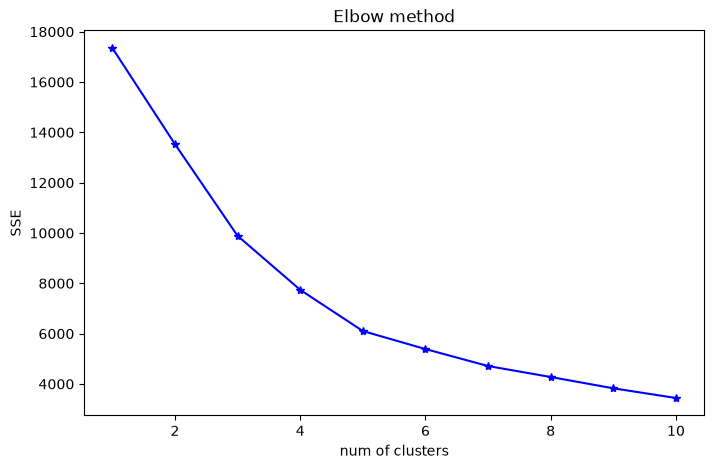

In [54]:
sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=1)
    kmeans.fit(rfm_s_df)
    sse.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11), sse, 'b-*')
plt.title('Elbow method')
plt.xlabel('num of clusters')
plt.ylabel('SSE')
plt.show()

The plot shows the SSE dropping sharply around k = 4-5 before plateauing. The optimal k lies in that range. Cross check with silhouette score for the different Ks.

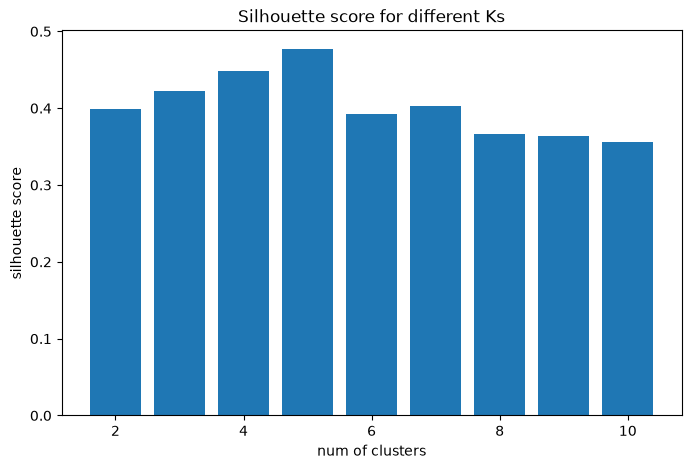

In [55]:
silhouette = []  #score is only defined for k >= 2, unlike SSE where it can be >= 1.
for k in range(2,11):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=1)
    labels = kmeans.fit_predict(rfm_s_df)
    silhouette.append(silhouette_score(rfm_s_df, labels))

plt.figure(figsize=(8,5))
plt.bar(range(2,11), silhouette)
plt.title('Silhouette score for different Ks')
plt.xlabel('num of clusters')
plt.ylabel('silhouette score')
plt.show()

In [56]:
for k, s in zip(range(2,11), silhouette):
    print(f'k={k}: silhouette - {s:.4f}')  #zip: pairs each number (representing k) with its corresponding silhouette score

k=2: silhouette - 0.3984
k=3: silhouette - 0.4220
k=4: silhouette - 0.4480
k=5: silhouette - 0.4773
k=6: silhouette - 0.3928
k=7: silhouette - 0.4034
k=8: silhouette - 0.3668
k=9: silhouette - 0.3633
k=10: silhouette - 0.3558


k = 5 produces the highest silhouette score while also sitting at the bend of the elbow plot. Therefore, k=5 will be chosen as the optimal k value. 

#### Build KMeans model

In [57]:
k = 5

km = KMeans(n_clusters=k, n_init=20, random_state=1)
rfm['km_cluster'] = km.fit_predict(rfm_s_df)

print(f'k means cluster sizes:\n{rfm['km_cluster'].value_counts().sort_index()}')
print(f'silhouette score (k=5): {silhouette_score(rfm_s_df, rfm['km_cluster'])}')

k means cluster sizes:
km_cluster
0    2737
1    1016
2     335
3       9
4     241
Name: count, dtype: int64
silhouette score (k=5): 0.47726905246431717


<hr>

#### Build Hierarchical(Agglomerative) clustering model
First, generate dendrogram with linkage=Ward

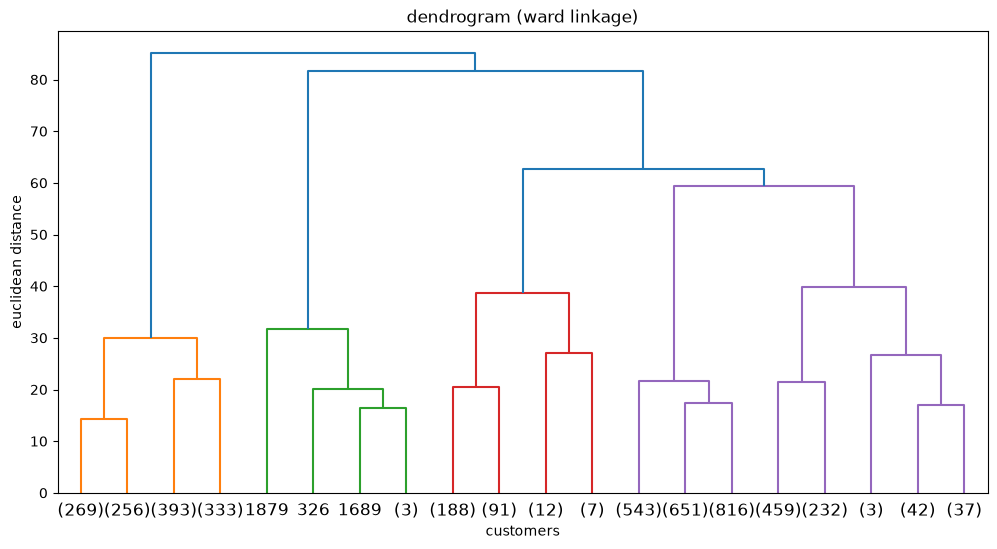

In [58]:
z = shc.linkage(rfm_s_df, method='ward')

plt.figure(figsize=(12,6))
plt.title('dendrogram (ward linkage)')
plt.xlabel('customers')
plt.ylabel('euclidean distance')
shc.dendrogram(z, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.show()

By calcualting the mid point of the longest vertical section that does not intersect any horizontal lines. with the max around 85 and starts around 30. the length of the section is around 55. 55/2 is 27.5. Add 27.5 to the start of the line (30) and add a line at y=30+27.5=57.5. 

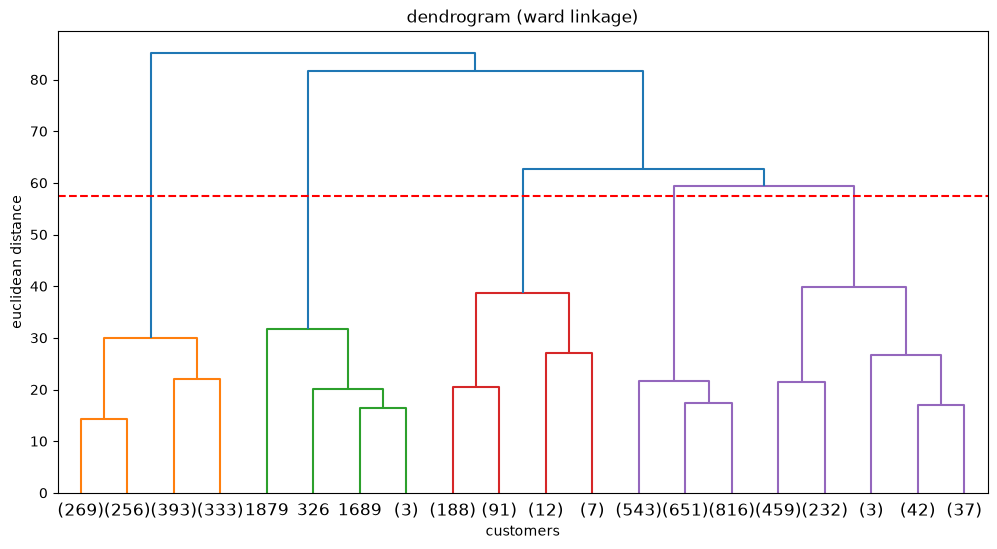

In [59]:
plt.figure(figsize=(12,6))
plt.title('dendrogram (ward linkage)')
plt.xlabel('customers')
plt.ylabel('euclidean distance')
shc.dendrogram(z, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.axhline(y=57.5, c='red', linestyle='--')
plt.show()

The optimal number of clusters will be the number of vertical lines that intersect the newly added red horizontal line. From that, the optimal k from this method is 5. However, I will cross check with the silhouette scores from the different Ks.

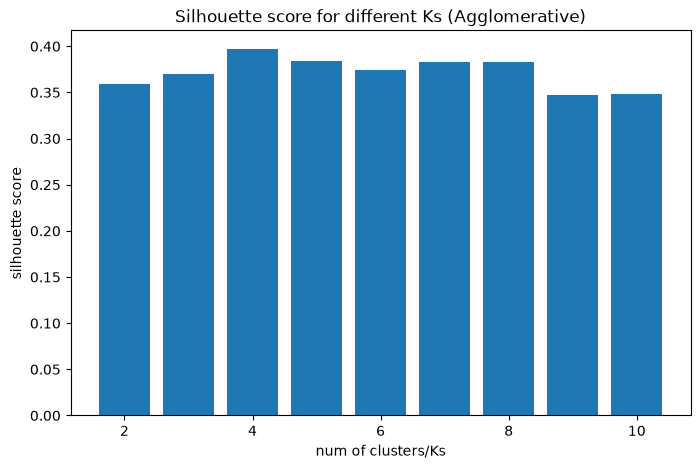

In [60]:
hier_silhouette = []  #score is only defined for k >= 2
for k in range(2,11):
    agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = agg.fit_predict(rfm_s_df)
    hier_silhouette.append(silhouette_score(rfm_s_df, labels))

plt.figure(figsize=(8,5))
plt.bar(range(2,11), hier_silhouette)
plt.title('Silhouette score for different Ks (Agglomerative)')
plt.xlabel('num of clusters/Ks')
plt.ylabel('silhouette score')
plt.show()

In [61]:
for k, s in zip(range(2,11), hier_silhouette):
    print(f'k={k}: silhouette = {s:.4f}')

k=2: silhouette = 0.3587
k=3: silhouette = 0.3701
k=4: silhouette = 0.3972
k=5: silhouette = 0.3842
k=6: silhouette = 0.3738
k=7: silhouette = 0.3831
k=8: silhouette = 0.3833
k=9: silhouette = 0.3477
k=10: silhouette = 0.3484


From the silhouette score, the highest score came from k=4, but k=5 is only a little lower and I decided to use it here to keep the number of clusters consisten with the final K-Means model, so during comparison, the 2 can have equal footing in this aspect. 
#### Build the Hierarchical/Agglomerative Clustering Model

In [62]:
hier = AgglomerativeClustering(n_clusters=5, linkage='ward')
rfm['hier_cluster'] = hier.fit_predict(rfm_s_df)

print(f'Agglo cluster sizes:\n{rfm['hier_cluster'].value_counts().sort_index()}')
print(f'silhouette score (k=5): {silhouette_score(rfm_s_df, rfm['hier_cluster'])}')

Agglo cluster sizes:
hier_cluster
0     773
1     298
2       6
3    1251
4    2010
Name: count, dtype: int64
silhouette score (k=5): 0.384178967281058


### 2.4 Evaluate and Compare the Models

#### Visualise K means cluster. 
'Monetary' is transformed with log because it is skewed and it would disrupt the scatter plot. 

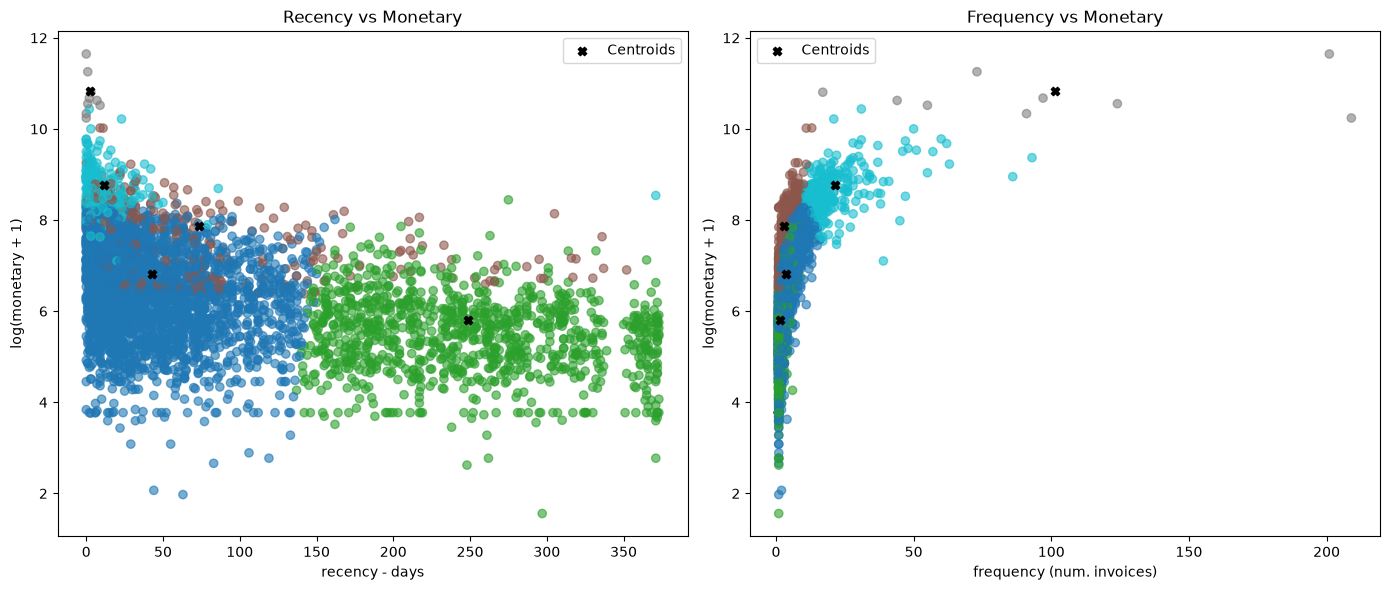

In [63]:
# inverse-transform centroids back into original (unscaled) units
og_centers = rfm_scaler.inverse_transform(km.cluster_centers_)
centers_df = pd.DataFrame(og_centers, columns=feat)  # feat=['Recency','Frequency','Monetary','AvgVal']

fig, axes = plt.subplots(1, 2, figsize=(14,6))

#use unscaled rfm to have interpretablility. when i used the scaled rfm, its hard to interpret clusters.

axes[0].scatter(rfm['Recency'], np.log1p(rfm['Monetary']), c=rfm['km_cluster'], cmap='tab10', alpha=0.6)
axes[0].scatter(centers_df['Recency'], np.log1p(centers_df['Monetary']), c='black', marker='X', label='Centroids')
axes[0].set_xlabel('recency - days')
axes[0].set_ylabel('log(monetary + 1)')
axes[0].set_title('Recency vs Monetary')
axes[0].legend()

# Frequency vs Monetary
axes[1].scatter(rfm['Frequency'], np.log1p(rfm['Monetary']), c=rfm['km_cluster'], cmap='tab10', alpha=0.6)
axes[1].scatter(centers_df['Frequency'], np.log1p(centers_df['Monetary']), c='black', marker='X', label='Centroids')
axes[1].set_xlabel('frequency (num. invoices)')
axes[1].set_ylabel('log(monetary + 1)')
axes[1].set_title('Frequency vs Monetary')
axes[1].legend()

plt.tight_layout()
plt.show()

Here, I used the scaled rfm to plot the scatter plot.

So sorry i meant to transformed instead of scaled in the video. 

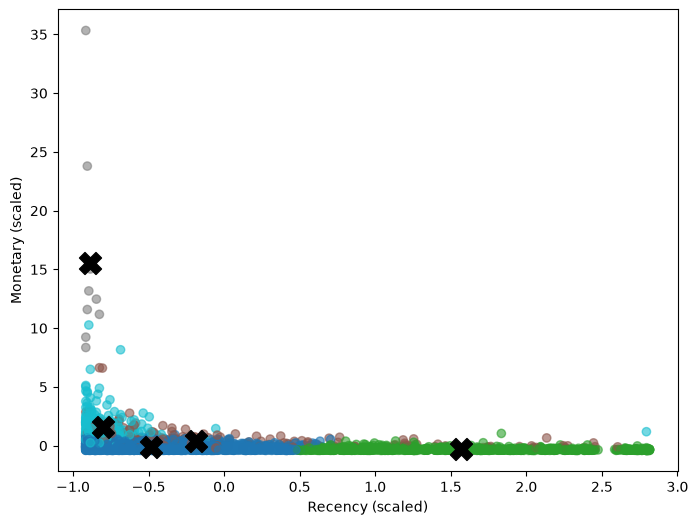

In [64]:
plt.figure(figsize=(8,6))
plt.scatter(rfm_s_df['Recency'], rfm_s_df['Monetary'], c=rfm['km_cluster'], cmap='tab10', alpha=0.6)
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,2], s=250, c='black', marker='X')  # col 0=Recency, col 2=Monetary
plt.xlabel('Recency (scaled)')
plt.ylabel('Monetary (scaled)')
plt.show()

As you can see, it is hard to form any actionable interpretability for the business, as the axis are not the actual values of the raw data points.

<hr>

##### Visualise agglomerative clustersusing the same feature pairs to create a direct comparison against k-means

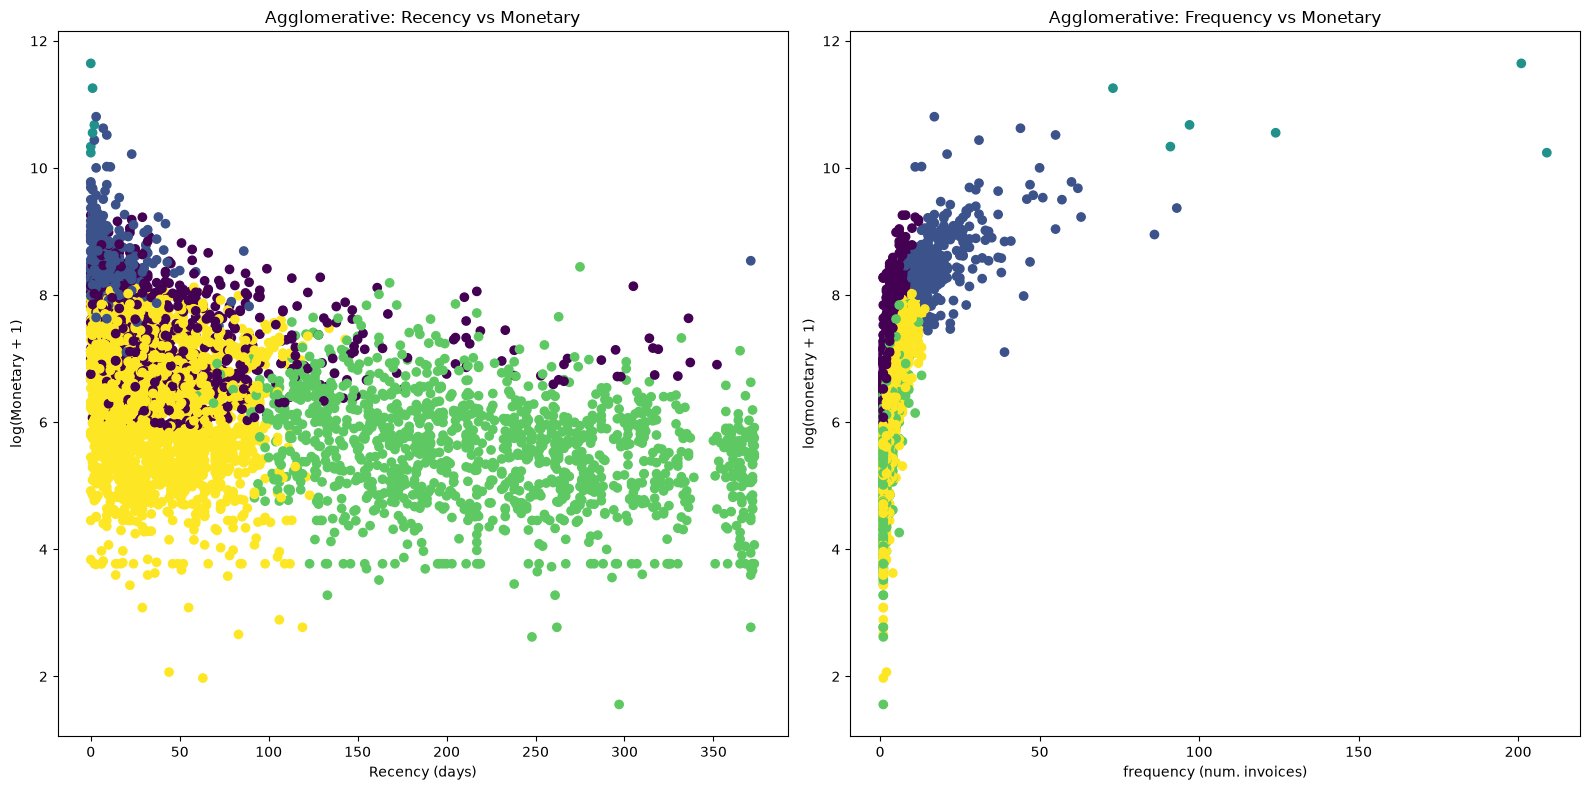

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(16,8))

axes[0].scatter(rfm['Recency'], np.log1p(rfm['Monetary']), c=rfm['hier_cluster'])
axes[0].set_title('Agglomerative: Recency vs Monetary')
axes[0].set_xlabel('Recency (days)')
axes[0].set_ylabel('log(Monetary + 1)')

axes[1].scatter(rfm['Frequency'], np.log1p(rfm['Monetary']), c=rfm['hier_cluster'])
axes[1].set_title('Agglomerative: Frequency vs Monetary')
axes[1].set_xlabel('frequency (num. invoices)')
axes[1].set_ylabel('log(monetary + 1)')

plt.tight_layout()
plt.show()

<hr>

#### RFM feature distribution across the clusters for each model using boxplots.
##### K-Means Cluster

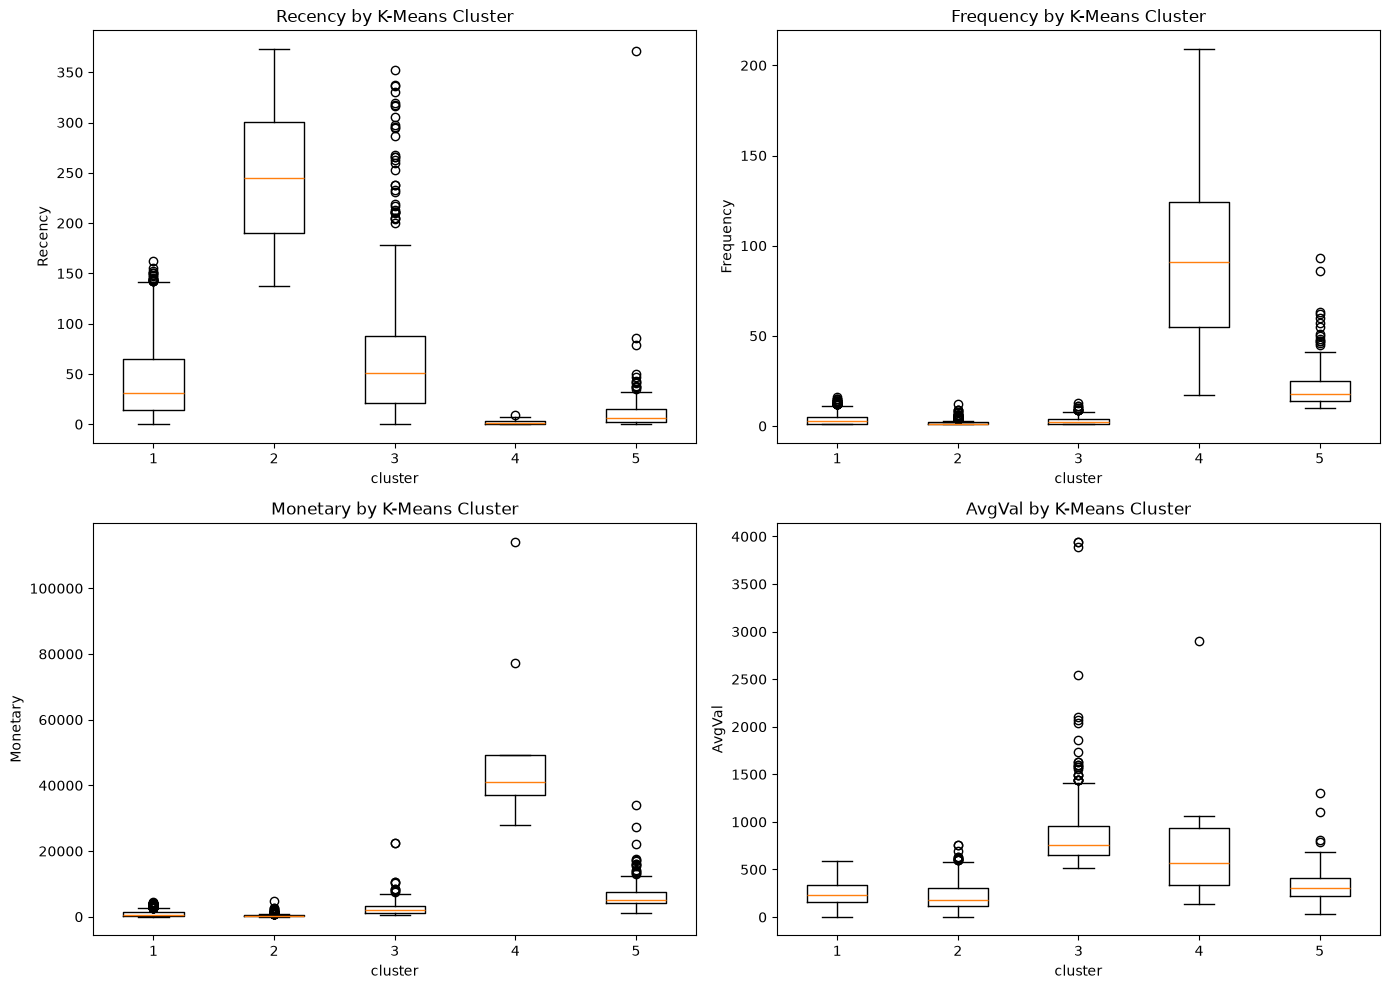

In [66]:
features = ['Recency', 'Frequency', 'Monetary', 'AvgVal']

fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.ravel()

for i, feat in enumerate(features):
    data_by_cluster = [rfm[rfm['km_cluster'] == c][feat] for c in sorted(rfm['km_cluster'].unique())]
    axes[i].boxplot(data_by_cluster, label=sorted(rfm['km_cluster'].unique()))
    axes[i].set_title(f'{feat} by K-Means Cluster')
    axes[i].set_xlabel('cluster')
    axes[i].set_ylabel(feat)

plt.tight_layout()
plt.show()

##### Agglomerative Cluster

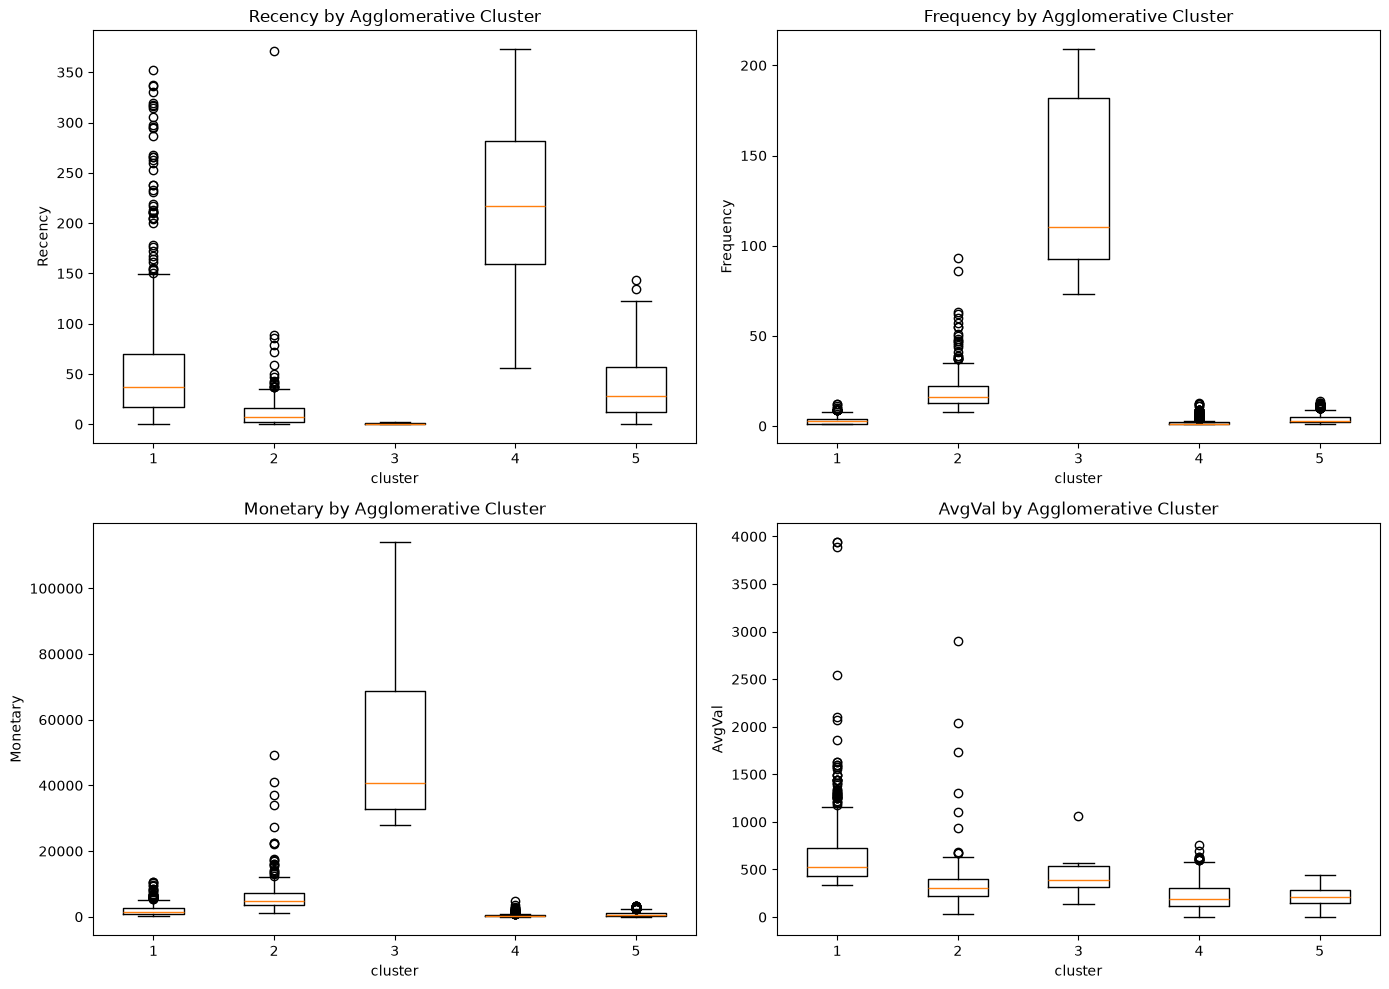

In [67]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.ravel()

for i, feat in enumerate(features):
    data_by_cluster = [rfm[rfm['hier_cluster'] == c][feat] for c in sorted(rfm['hier_cluster'].unique())]
    axes[i].boxplot(data_by_cluster, label=sorted(rfm['hier_cluster'].unique()))
    axes[i].set_title(f'{feat} by Agglomerative Cluster')
    axes[i].set_xlabel('cluster')
    axes[i].set_ylabel(feat)

plt.tight_layout()
plt.show()

<hr>

### Compare silhouette scores of both models at k=5.

In [68]:
compare = pd.DataFrame({'Model': ['K-Means', 'Agglomerative'],
                        'k': [5, 5],
                        'silhouette score':[silhouette_score(rfm_s_df, rfm['km_cluster']),
                                            silhouette_score(rfm_s_df, rfm['hier_cluster'])]})
compare

,Model,k,silhouette score
0,K-Means,5,0.477269
1,Agglomerative,5,0.384179


The K-Means model has the higher silhouette score, indicating that its clusters are more compact and better separated compared to the agglomerative model. **K-Means will therefore be chosen as the preferred model** for further exploration and segment interpretation. <hr>

### Assign behaviour to segments

Get the mean for RFM to better understand customer behaviour per segment. 

In [69]:
cluster_mean = rfm.groupby('km_cluster')[features].agg(['mean', 'count'])
cluster_mean

Recency         Frequency            Monetary        \
                  mean count        mean count          mean count   
km_cluster                                                           
0            42.870296  2737    3.599196  2737    917.368631  2737   
1           248.488189  1016    1.557087  1016    329.774094  1016   
2            73.143284   335    3.089552   335   2599.037734   335   
3             2.555556     9  101.222222     9  51079.802222     9   
4            11.448133   241   21.381743   241   6418.961120   241   

                AvgVal        
                  mean count  
km_cluster                    
0           253.809620  2737  
1           216.786542  1016  
2           882.646047   335  
3           818.872465     9  
4           327.114837   241

***Refresher*** <br>
Recency: days since the customer's last purchase (mean=248 = the average last purchase made was 248 days ago) - <b>bigger = worse</b><br>
Frequency: how many orders the same customer placed - **bigger = better**<br>
Monetary: how much money a customer spent in total, across all their orders - **bigger = better**

To allow for easier interpretability, assign non-technical names to the segmenets based on their segment.

In [70]:
names = {
    0: 'active reoccurring customers',
    1: 'at-risk-of-losing customers',
    2: 'occasional high spenders',
    3: 'top-tier highest spenders',
    4: 'recent high spending customers'
}

rfm['Segments'] = rfm['km_cluster'].map(names)
rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary', 'AvgVal', 'Segments']].head()

,CustomerID,Recency,Frequency,Monetary,AvgVal,Segments
0,12346.0,325,1,42.48,42.480000,at-risk-of-losing customers
1,12347.0,1,7,3769.34,538.477143,active reoccurring customers
2,12348.0,74,4,1111.40,277.850000,active reoccurring customers
3,12349.0,18,1,1442.71,1442.710000,occasional high spenders
4,12350.0,309,1,334.40,334.400000,at-risk-of-losing customers


<hr>

## 2.5 Summarize and Interpret

In [71]:
summary_table = rfm.groupby('Segments')[['Recency','Frequency','Monetary','AvgVal']].mean().round(1)
summary_table['num custs'] = rfm['Segments'].value_counts()
summary_table = summary_table.sort_values('Monetary', ascending=False)
summary_table

,Recency,Frequency,Monetary,AvgVal,num custs
Segments,,,,,
top-tier highest spenders,2.6,101.2,51079.8,818.9,9
recent high spending customers,11.4,21.4,6419.0,327.1,241
occasional high spenders,73.1,3.1,2599.0,882.6,335
active reoccurring customers,42.9,3.6,917.4,253.8,2737
at-risk-of-losing customers,248.5,1.6,329.8,216.8,1016


K-Means (k=5) was preferred over Agglomerative Clustering on silhouette score (0.477 vs 0.384), and its 5 clusters mapped cleanly into interpretable segments. 

<hr>

**Segment interpretation and their corresponding business actions that can be taken**
| | Recency | Frequency | Monetary |
| --- | --- | --- | --- |
| top-tier highest spenders | very low | very high | very high |
| recent high spending customers | low | high | high |
| occasional high spenders | moderate | low-moderate | high |
| active reoccurring customers | low | moderate | moderate |
| at-risk-of-losing customers | very high | low | low |


**top-tier highest spenders**: Since they are a small group, it is best to retain them at all cost. This can be done with dedicated personal account management, exclusive offers/discounts, and maybe even early access to new products.<br>
**recent high spending customers**: The company can slowly nurture this group with loyalty rewards and try to upsell offers to push them towards the top-tier highest spenders segment. This segment has strongest potential top-tier highest spenders customers. <br>
**occasional high spenders**: This group can be targeted with occasional reminder to shop, since they spend quite a bit every visit, but do not visit often.<br>
**active reoccurring customers**: The largest group and the middle ground. The organization can strive to maintain frequent engagement with promotions with this particular group. They can also cross-sell to increase this group's basket size. <br>
**at-risk-of-losing customers**: The organization can send win-back campaign to these customers' emails and discounts before they completely lose engagement. This is a low cost recommendation too as it can be automated. 

In summary, K-Means was the better clustering model for customer segmentation. This was concluded from the visual separation of the clusters and its silhouette score. The online retailer should consider taking action for these groups increaase its profit long-term. 